![lyon2 geonum](https://perso.liris.cnrs.fr/lmoncla/GEONUM/fig/logos.png)

# 2F2 – Gestion et traitement des données spatio-temporelles

## Tutoriel : Analyse des disponibilités des stations Vélo'v de la Métropole de Lyon

# Séance 1 : Exploration des données avec Pandas


L'objectif de ce tutoriel est d'appréhender la problématique d'analyse de données spatio-temporelles grâce à l'utilisation de librairies Python.
Pour cela nous allons travailler sur un cas d'étude visant la visualisation et le traitement des données de disponibilités des stations Vélo'v de la Métropole de Lyon. 

Les objectifs de ce tutoriel sont les suivants : 

* Récupérer le jeu de données, analyser sa structure et le charger dans un dataframe
* Explorer et visualiser les données
* Analyser les données 

Les données que nous allons utilisées proviennent de la [plateforme data du Grand Lyon](https://data.grandlyon.com). 
Nous utiliserons deux jeux de données :
1. **la liste des stations Vélo'v** (localisation, nom, commune, nombre de bornettes), récupérée en direct depuis l'API du Grand Lyon ;
2. **l'historique des disponibilités** des stations du 01/07/2025 au 30/06/2026, avec un relevé par station toutes les 30 minutes. Ce fichier a été généré via un script à partir des données du Grand Lyon



**Comment utiliser ce notebook** : chaque notion est illustrée par un exemple commenté, puis suivie d'un ou plusieurs exercices à faire vous-même dans la cellule vide qui suit

⚠️ **Les exercices s'enchaînent** : les colonnes créées dans un exercice (par exemple `est_weekend` ou `commune`) sont réutilisées plus loin. Si vous êtes bloqué, demandez la correction de l'exercice avant de passer à la suite.

Cheat sheet utile : [Pandas Cheat Sheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf)

## 1. Importer les librairies

In [ ]:
import pandas as pd
import numpy as np
import requests
import plotly.express as px
import geopandas as gpd

# chemin vers le fichier d'historique des disponibilités de vélos
FICHIER_HISTO = "../data/velov_dispo_30min_2025-07-01_2026-06-30.csv.gz"

## 2. Charger la liste des stations depuis une API

De nombreux portails de données ouvertes proposent une **API** (*Application Programming Interface*) : une adresse web que l'on interroge depuis un programme et qui renvoie des données, souvent au format **JSON**.

Le Grand Lyon publie la liste des stations Vélo'v à l'adresse ci-dessous. Vous pouvez l'ouvrir dans votre navigateur pour voir à quoi ressemble la réponse.

Avec Python, on utilise la librairie `requests` :
- `requests.get(url)` envoie la requête et renvoie une réponse ;
- `reponse.status_code` vaut `200` si tout s'est bien passé ;
- `reponse.json()` transforme la réponse JSON en **dictionnaire** Python.

In [ ]:
from plotly import data


URL_STATIONS = ("https://data.grandlyon.com/fr/datapusher/ws/grandlyon/"
                "pvo_patrimoine_voirie.pvostationvelov/all.json?maxfeatures=-1")

reponse = requests.get(URL_STATIONS, timeout=60)
print("Code de retour :", reponse.status_code)

data_histo = reponse.json()
type(data_histo)

Code de retour : 200


dict

Un dictionnaire associe des **clés** à des **valeurs**. On affiche ses clés pour comprendre comment la réponse est organisée :

In [ ]:
data_histo.keys()

dict_keys(['fields', 'layer_name', 'nb_results', 'table_alias', 'table_href', 'values'])

### Exercice 2.1 – Explorer la réponse de l'API

1. Affichez le nombre de résultats renvoyés par l'API (clé `nb_results`) - DONC LE NOMBRE DE STATIONS.
2. Affichez la liste des champs disponibles (clé `fields`).
3. Affichez le **premier élément** de la liste `values` : à quoi correspond-il ?

<details><summary>💡 Indice</summary>

`donnees["cle"]` permet d'accéder à la valeur associée à une clé. `values` est une liste : son premier élément est `donnees["values"][0]`.

</details>

In [ ]:
# REPONSES ICI

Pour manipuler ces données nous allons utiliser les [dataframes](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html) de la librairie Pandas.

Pandas est une librairie Python spécialisée dans l'analyse et la manipulation de données. Elle fourni en particulier un objet de type 'dataframe' qui permet de réaliser des opérations de prétraitement et de filtrage que nous utiliserons pour requêter les données.

La clé `values` contient une **liste de dictionnaires** (un par station). C'est exactement ce que pandas sait transformer en tableau : un **DataFrame**.


In [ ]:
df_stations = pd.DataFrame(data_histo["values"])
df_stations.head()

,achevement,adresse1,adresse2,code_insee,commune,gid,idstation,lat,lon,nbbornettes,nom,numdansarrondissement,ouverte,pole,stationbonus,validite
0,Monté,"Face 140, Rue Bataille",None,69388,Lyon 8e Arrondissement,1,8050,45.736268,4.879737,18,Bataille / Krüger,NaN,True,Logements,None,Validé
1,Monté,"41, Quai Rambaud",Angle Rue Hrant Dink,69382,Lyon 2e Arrondissement,31,2009,45.739543,4.815131,26,Confluence / Docks,9.0,True,Confluence - Les Docks,None,Validé
2,Monté,"Face 40, Quai Chauveau",Angle Pont Général Koenig,69389,Lyon 9e Arrondissement,32,9011,45.769782,4.812676,19,Conservatoire,11.0,True,Conservatoire National de Musique,None,Validé
3,Monté,"111, Rue Paul Bert",Face Place des Martyrs de la Résistance,69383,Lyon 3e Arrondissement,60,3037,45.757103,4.853482,21,Paul Bert / Garibaldi,37.0,True,Maillage - Piscine Garibaldi - MdL,None,Validé
4,Monté,"Face 1, Rue Valentin Haüy",None,69266,Villeurbanne,20,10110,45.759574,4.882735,24,Mémoire et Société,110.0,True,Centre Mémoire et Société - Itinéraire cyclable,None,Validé


### Exercice 2.2 – Sauvegarder les stations

Enregistrez `df_stations` dans le fichier `../data/stations_velov.csv` avec la méthode [`to_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html), **sans** la colonne d'index.
Relisez ensuite le fichier avec `pd.read_csv()` et vérifiez que vous retrouvez bien le même nombre de lignes.

*Pourquoi sauvegarder ?* L'API renvoie l'état **actuel** des stations : en gardant une copie, vos analyses restent reproductibles même si l'API change.

<details><summary>💡 Indice</summary>

`df.to_csv(chemin, index=False)`

</details>

In [ ]:
# REPONSES ICI

## 3. Premier regard sur un DataFrame

Avant toute analyse, on prend le temps de **regarder** les données : dimensions, colonnes, types, valeurs manquantes, ordres de grandeur.

In [ ]:
## Dimensions (lignes, colonnes)
df_stations.shape

(457, 16)

In [ ]:
## On affiche les premières lignes
df_stations.head()
##... Ou les dernières lignes
df_stations.tail()

In [ ]:
## Noms des colonnes
df_stations.columns

In [ ]:
## Types des colonnes, nombre de valeurs non nulles, mémoire utilisée
df_stations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   achevement             457 non-null    object 
 1   adresse1               457 non-null    object 
 2   adresse2               201 non-null    object 
 3   code_insee             456 non-null    object 
 4   commune                456 non-null    object 
 5   gid                    457 non-null    int64  
 6   idstation              457 non-null    int64  
 7   lat                    457 non-null    float64
 8   lon                    457 non-null    float64
 9   nbbornettes            457 non-null    int64  
 10  nom                    457 non-null    object 
 11  numdansarrondissement  348 non-null    float64
 12  ouverte                457 non-null    bool   
 13  pole                   441 non-null    object 
 14  stationbonus           0 non-null      object 
 15  validi

In [ ]:
## Statistiques descriptives des colonnes numériques
df_stations.describe()

In [ ]:
## Quelques lignes tirées au hasard (souvent plus représentatif que head())
df_stations.sample(5)

In [ ]:
## accéder à une colonne
df_stations["commune"]

0      Lyon 8e Arrondissement
1      Lyon 2e Arrondissement
2      Lyon 9e Arrondissement
3      Lyon 3e Arrondissement
4                Villeurbanne
                ...          
452    Lyon 6e Arrondissement
453              Villeurbanne
454    Lyon 7e Arrondissement
455    Lyon 3e Arrondissement
456    Lyon 3e Arrondissement
Name: commune, Length: 457, dtype: object

In [ ]:
## Comptage des valeurs d'une colonne
df_stations["commune"].value_counts()

commune
Villeurbanne                  82
Lyon 3e Arrondissement        61
Lyon 7e Arrondissement        48
Lyon 8e Arrondissement        37
Lyon 2e Arrondissement        37
Lyon 6e Arrondissement        32
Lyon 9e Arrondissement        28
Lyon 5e Arrondissement        28
Lyon 4e Arrondissement        20
Lyon 1er Arrondissement       20
Vénissieux                    13
Vaulx-en-Velin                 6
Caluire-et-Cuire               5
Saint-Fons                     5
Oullins                        4
Bron                           4
Rillieux-la-Pape               2
Saint-Genis-Laval              2
Décines-Charpieu               2
Neuville-sur-Saône             2
Saint-Priest                   2
Fontaines-sur-Saône            2
Collonges-au-Mont-d'Or         2
Chassieu                       1
Écully                         1
Albigny-sur-Saône              1
Tassin-la-Demi-Lune            1
Saint-Didier-au-Mont-d'Or      1
La Mulatière                   1
Champagne-au-Mont-d'Or         1
Sa

In [ ]:
## Afficher une colonne triée par ordre croissant ou décroissant
communes_triees = df_stations['commune'].sort_values(ascending=True)  # croissant
display(communes_triees)

## Trier un dataframe par une ou plusieurs colonnes
df_trie = df_stations.sort_values(by=["commune","nbbornettes"], ascending=[True,False])
display(df_trie[["nom", "commune","nbbornettes"]])

##Et créer un nouveau dataframe trié avec un nouvel index
df_trie_index = df_stations.sort_values(by=["commune","nbbornettes"], ascending=[True,False])[["nom", "commune","nbbornettes"]].reset_index(drop=True)
display(df_trie_index)

10     Albigny-sur-Saône
364                 Bron
377                 Bron
395                 Bron
382                 Bron
             ...        
300           Vénissieux
297           Vénissieux
106           Vénissieux
32                Écully
301                 None
Name: commune, Length: 457, dtype: object

,nom,commune,nbbornettes
10,Albigny - Gare,Albigny-sur-Saône,18
395,Bron - Université,Bron,30
382,Bron - Place Curial,Bron,25
364,Bron - Mairie,Bron,23
377,Bron - Centre Nautique,Bron,13
...,...,...,...
300,Vénissieux - Martyrs de la Résistance,Vénissieux,15
53,Vénissieux - Farge / Clochettes,Vénissieux,12
297,Vénissieux - Bruant / Cagne,Vénissieux,10
32,Ecully - Mairie,Écully,12


,nom,commune,nbbornettes
0,Albigny - Gare,Albigny-sur-Saône,18
1,Bron - Université,Bron,30
2,Bron - Place Curial,Bron,25
3,Bron - Mairie,Bron,23
4,Bron - Centre Nautique,Bron,13
...,...,...,...
452,Vénissieux - Martyrs de la Résistance,Vénissieux,15
453,Vénissieux - Farge / Clochettes,Vénissieux,12
454,Vénissieux - Bruant / Cagne,Vénissieux,10
455,Ecully - Mairie,Écully,12


### Exercice 3.1 – Combien ?

1. Combien y a-t-il de stations Vélo'v ?
2. Dans combien de communes différentes sont-elles implantées ?
3. Combien y a-t-il de bornettes (emplacements) au total ?

<details><summary>💡 Indice</summary>

`len()`, `.nunique()`, `.sum()`

</details>

In [ ]:
# REPONSES ICI


9585

### Exercice 3.2 – La plus grande station

Quelle est la station qui possède le plus de bornettes ? Affichez son nom, sa commune et son nombre de bornettes.
Affichez ensuite les **5 plus petites** stations.

<details><summary>💡 Indice</summary>

`sort_values(colonne, ascending=False)`, ou `nlargest()` / `nsmallest()`.

</details>

In [ ]:
# REPONSES ICI


,nom,commune,nbbornettes
366,INSA,Villeurbanne,55


### Exercice 3.3 – Valeurs manquantes et stations fermées

1. Combien de valeurs manquantes y a-t-il dans chaque colonne ?
2. Combien de stations sont actuellement fermées (colonne `ouverte`) ?

<details><summary>💡 Indice</summary>

`df.isna().sum()` compte les valeurs manquantes colonne par colonne.

</details>

In [ ]:
# REPONSES ICI


## 4. Sélectionner et filtrer

### 4.1 Sélectionner des colonnes

In [ ]:
## Une colonne -> Series
df_stations["nom"].head()

0        Bataille / Krüger
1       Confluence / Docks
2            Conservatoire
3    Paul Bert / Garibaldi
4       Mémoire et Société
Name: nom, dtype: object

In [ ]:
## Plusieurs colonnes -> DataFrame (on passe une LISTE de noms)
df_stations[["nom", "commune", "nbbornettes"]].head()

,nom,commune,nbbornettes
0,Bataille / Krüger,Lyon 8e Arrondissement,18
1,Confluence / Docks,Lyon 2e Arrondissement,26
2,Conservatoire,Lyon 9e Arrondissement,19
3,Paul Bert / Garibaldi,Lyon 3e Arrondissement,21
4,Mémoire et Société,Villeurbanne,24


### 4.2 Sélectionner par position (`iloc`) ou par étiquette (`loc`)

- `df.iloc[lignes, colonnes]` : sélection par **position** (0, 1, 2…), comme dans une matrice ;
- `df.loc[lignes, colonnes]` : sélection par **étiquette** (index et noms de colonnes) ou par **condition**.

In [ ]:
## 3 premières lignes, 2 premières colonnes
df_stations.iloc[0:3, 0:2]

,achevement,adresse1
0,Monté,"Face 140, Rue Bataille"
1,Monté,"41, Quai Rambaud"
2,Monté,"Face 40, Quai Chauveau"


In [ ]:
## Dernière ligne (indice négatif)
df_stations.iloc[-1]

achevement                                                  Monté
adresse1                                      59, Boulevard Pinel
adresse2                                                     None
code_insee                                                  69383
commune                                    Lyon 3e Arrondissement
gid                                                           421
idstation                                                    3091
lat                                                     45.748285
lon                                                       4.89697
nbbornettes                                                    19
nom                                          Hôpital Neurologique
numdansarrondissement                                        91.0
ouverte                                                      True
pole                     Centre hospitalier - Itinéraire cyclable
stationbonus                                                 None
validite  

In [ ]:
## Lignes d'index 0 à 4 (inclus avec loc !), colonnes choisies par leur nom
df_stations.loc[0:4, ["nom", "commune"]]

,nom,commune
0,Bataille / Krüger,Lyon 8e Arrondissement
1,Confluence / Docks,Lyon 2e Arrondissement
2,Conservatoire,Lyon 9e Arrondissement
3,Paul Bert / Garibaldi,Lyon 3e Arrondissement
4,Mémoire et Société,Villeurbanne


### 4.3 Filtrer avec des conditions

Une condition sur une colonne renvoie une `Series` de booléens (`True`/`False`). Placée dans `loc[]`, elle ne garde que les lignes `True`.

On combine les conditions avec `&` (ET), `|` (OU) et `~` (NON), **en mettant chaque condition entre parenthèses**.

In [143]:
## Stations de plus de 40 bornettes
df_stations.loc[df_stations["nbbornettes"] > 40, ["nom", "commune", "nbbornettes"]]

,nom,commune,nbbornettes
311,Hôtel Dieu / Pont de la Guillotière,Lyon 2e Arrondissement,50
330,Charpennes,Villeurbanne,46
366,INSA,Villeurbanne,55
411,Opéra,Lyon 1er Arrondissement,41


In [144]:
## Stations du 1er arrondissement ET de moins de 15 bornettes
df_stations.loc[(df_stations["commune"] == "Lyon 1er Arrondissement") & (df_stations["nbbornettes"] < 15),
                ["nom", "nbbornettes"]]

,nom,nbbornettes
66,Terreaux / Beaux Arts,11
345,Martinière,11


In [145]:
## Appartenance à une liste de valeurs : isin()
communes = ["Vénissieux", "Vaulx-en-Velin"]
df_stations.loc[df_stations["commune"].isin(communes), ["nom", "commune"]]

,nom,commune
11,Vaulx - Hôtel de ville,Vaulx-en-Velin
53,Vénissieux - Farge / Clochettes,Vénissieux
106,Vénissieux - Coblod,Vénissieux
107,Vénissieux - Paul / Picard,Vénissieux
122,Vénissieux - Gare,Vénissieux
201,Moulin à Vent,Vénissieux
297,Vénissieux - Bruant / Cagne,Vénissieux
298,Vaulx - Médiathèque,Vaulx-en-Velin
299,Vénissieux - Mairie,Vénissieux
300,Vénissieux - Martyrs de la Résistance,Vénissieux


In [146]:
## Même filtre écrit avec query() : plus lisible pour les conditions longues
df_stations.query("nbbornettes > 40 and commune != 'Villeurbanne'")[["nom", "commune", "nbbornettes"]]

,nom,commune,nbbornettes
311,Hôtel Dieu / Pont de la Guillotière,Lyon 2e Arrondissement,50
411,Opéra,Lyon 1er Arrondissement,41


Pour les colonnes de texte, l'accesseur `.str` donne accès aux méthodes de chaînes de caractères : `.str.contains()`, `.str.startswith()`, `.str.upper()`…

In [147]:
df_stations.loc[df_stations["nom"].str.contains("Part-Dieu", case=False), ["nom", "commune"]]


,nom,commune
8,Part-Dieu / Francfort,Lyon 3e Arrondissement
51,Part-Dieu / Garibaldi,Lyon 3e Arrondissement
67,Part-Dieu / Pompidou,Lyon 3e Arrondissement
110,Part-Dieu / Deruelle,Lyon 3e Arrondissement
134,Part-Dieu / Cuirassiers,Lyon 3e Arrondissement
249,Part-Dieu / Villette,Lyon 3e Arrondissement
406,Part-Dieu / Cuirassiers,Lyon 3e Arrondissement
422,Liberté / Part-Dieu,Lyon 3e Arrondissement


⚠️ **Méthodes `.str` et valeurs manquantes : ** Sur une valeur manquante (`NaN`), `.str.contains()` ou `.str.startswith()` ne renvoient ni `True` ni `False`, mais `NaN`. Or `loc` refuse un filtre qui contient des `NaN` :

`ValueError: Cannot mask with non-boolean array containing NA / NaN values`

Le paramètre `na=False` indique quoi renvoyer pour les valeurs manquantes. Par exemple, une station n'a pas de commune renseignée :

In [153]:
## Sans na=False, cette ligne provoquerait une erreur
df_stations.loc[df_stations["commune"].str.contains("Villeurbanne", na=False), ["nom", "commune"]].head(3)

,nom,commune
4,Mémoire et Société,Villeurbanne
12,Ecole de musique,Villeurbanne
27,Boiron Granger,Villeurbanne


In [ ]:
## La station sans commune : on pourrait la compléter à partir de ses coordonnées
display(df_stations.loc[df_stations["commune"].isna(), ["idstation", "nom", "adresse1", "code_insee", "lat", "lon"]])

## On modifie donc les infos de la station 17006
df_stations.loc[df_stations["idstation"] == 17006, ["commune", "code_insee"]] = ["Saint-Fons", "69199"]

## On enregistre le dataframe modifié dans un nouveau fichier CSV
df_stations.to_csv("../data/velov_stations_corrige.csv", index=False)

,idstation,nom,adresse1,code_insee,lat,lon


### Exercice 4.1 – Grandes stations lyonnaises

Sélectionnez les stations situées **dans Lyon** (tous arrondissements confondus) et ayant **au moins 30 bornettes**. Combien sont-elles ? Triez-les par nombre de bornettes décroissant.

<details><summary>💡 Indice</summary>

Toutes les communes de Lyon commencent par `"Lyon "` : pensez à `.str.startswith()`. Si vous obtenez `ValueError: Cannot mask with non-boolean array containing NA / NaN values`, relisez l'encadré ci-dessus sur les valeurs manquantes.

</details>

In [158]:
# REPONSES ICI


### Exercice 4.2 – Les gares

Quelles stations ont le mot « gare » dans leur nom (quelle que soit la casse) ?

In [160]:
# REPONSE ICI


## 5. Charger et préparer l'historique des disponibilités de vélo'v

### 5.1 Le jeu de données

Le fichier `velov_dispo_30min_2025-07-01_2026-06-30.csv.gz` a été préparé à partir de l'API d'historique du Grand Lyon (`jcd_jcdecaux.historiquevelov`). Il contient, **pour chaque station et toutes les 30 minutes** :

| Colonne | Description |
|---|---|
| `horodate` | date et heure du créneau (heure de Paris) |
| `number` | numéro de la station (= `idstation` dans la table des stations) |
| `status` | `OPEN` ou `CLOSED` |
| `capacity` | nombre total d'emplacements |
| `bikes`, `mechanical_bikes`, `electrical_bikes` | vélos disponibles (total, mécaniques, électriques) |
| `stands` | emplacements libres |
| `departs_*`, `arrivees_*` | départs / arrivées estimés pendant la demi-heure **qui précède** le créneau |

*Comment sont estimés les départs et arrivées ?* Les données brutes ne contiennent que le nombre de vélos présents, relevé environ toutes les 3 minutes. Chaque baisse entre deux relevés compte comme des départs, chaque hausse comme des arrivées. Cela reste une **estimation** 

Le fichier est compressé (`.gz`) : `read_csv()` sait le lire directement, inutile de le décompresser.

In [346]:
df_velos = pd.read_csv(FICHIER_HISTO)
df_velos.head()

,horodate,number,status,capacity,bikes,stands,mechanical_bikes,electrical_bikes,departs_bikes,arrivees_bikes,departs_mechanical,arrivees_mechanical,departs_electrical,arrivees_electrical
0,2025-07-01T00:00:00+02:00,555,OPEN,3,0,3,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,2025-07-01T00:00:00+02:00,1001,OPEN,16,12,3,12,0,2.0,2.0,0.0,2.0,3.0,1.0
2,2025-07-01T00:00:00+02:00,1002,OPEN,41,1,36,1,0,8.0,4.0,5.0,1.0,3.0,3.0
3,2025-07-01T00:00:00+02:00,1003,OPEN,22,10,11,10,0,2.0,1.0,2.0,1.0,0.0,0.0
4,2025-07-01T00:00:00+02:00,1005,OPEN,16,11,5,11,0,1.0,0.0,1.0,0.0,0.0,0.0


In [335]:
df_velos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7504079 entries, 0 to 7504078
Data columns (total 14 columns):
 #   Column               Dtype  
---  ------               -----  
 0   horodate             object 
 1   number               int64  
 2   status               object 
 3   capacity             int64  
 4   bikes                int64  
 5   stands               int64  
 6   mechanical_bikes     int64  
 7   electrical_bikes     int64  
 8   departs_bikes        float64
 9   arrivees_bikes       float64
 10  departs_mechanical   float64
 11  arrivees_mechanical  float64
 12  departs_electrical   float64
 13  arrivees_electrical  float64
dtypes: float64(6), int64(6), object(2)
memory usage: 801.5+ MB


### 5.2 Réduire la mémoire utilisée

Afin d'optimiser la taille du dataframe, on peut retravailler certaines variable

On va :
1. convertir `horodate` en vraie date avec `pd.to_datetime()` ;
2. convertir `status`, qui ne prend que 2 valeurs, en type `category` ;
3. utiliser des types numériques plus petits (`int16` va jusqu'à 32 767, largement suffisant pour compter des vélos).  Pourquoi 32 767 ? 

In [347]:
## Les horodates contiennent un décalage horaire (+01:00 en hiver, +02:00 en été) :
## on les lit en UTC puis on les convertit en heure de Paris
df_velos["horodate"] = pd.to_datetime(df_velos["horodate"], utc=True).dt.tz_convert("Europe/Paris")
df_velos["status"] = df_velos["status"].astype("category")

df_velos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7504079 entries, 0 to 7504078
Data columns (total 14 columns):
 #   Column               Dtype                       
---  ------               -----                       
 0   horodate             datetime64[ns, Europe/Paris]
 1   number               int64                       
 2   status               category                    
 3   capacity             int64                       
 4   bikes                int64                       
 5   stands               int64                       
 6   mechanical_bikes     int64                       
 7   electrical_bikes     int64                       
 8   departs_bikes        float64                     
 9   arrivees_bikes       float64                     
 10  departs_mechanical   float64                     
 11  arrivees_mechanical  float64                     
 12  departs_electrical   float64                     
 13  arrivees_electrical  float64                     
dtypes:

### Exercice 5.1 – Des types plus légers

1. Convertissez `capacity`, `bikes`, `stands`, `mechanical_bikes`, `electrical_bikes` en `int16`.
2. Convertissez `number` en `int32`,
3. Les colonnes `departs_*` et `arrivees_*` contiennent quelques valeurs manquantes (vérifiez-le !) : supprimez ces lignes.
4. convertissez les colonnes `departs_*` et `arrivees_*` en `int16` 
5. Quelle est la nouvelle taille du DataFrame en mémoire?

<details><summary>💡 Indice</summary>

`df[liste_de_colonnes] = df[liste_de_colonnes].astype("int16")` 

supprimer des lignes contenant des valeurs nulles
`df = df.dropna(subset=liste_de_colonnes, how="any")` ==> how = any|all (supprimer les lignes pour lesquelles au moins une VS toutes les colonnes sont nulles)

</details>

In [242]:
# REPONSES ICI


### 5.3 Extraire des informations des dates

Une fois `horodate` au format date, l'accesseur `.dt` donne accès à ses composantes : `.dt.hour`, `.dt.minute`, `.dt.month`, `.dt.dayofweek` (0 = lundi … 6 = dimanche), `.dt.normalize()` (date sans l'heure)…

In [348]:
df_velos["heure"] = df_velos["horodate"].dt.hour.astype("int8")
df_velos["date"] = df_velos["horodate"].dt.tz_localize(None).dt.normalize()   # date du jour, sans l'heure
df_velos[["horodate", "heure", "date"]].sample(5)

,horodate,heure,date
708531,2025-08-05 23:00:00+02:00,23,2025-08-05
6490912,2026-05-15 00:30:00+02:00,0,2026-05-15
797926,2025-08-10 11:30:00+02:00,11,2025-08-10
5828159,2026-04-14 00:30:00+02:00,0,2026-04-14
6889414,2026-06-02 13:30:00+02:00,13,2026-06-02


### Exercice 5.2 – Jour de la semaine et week-end

Ajoutez ces colonnes :
- `annee` : le numéro de l'année;
- `mois` : le numéro du mois ;
- `jour` : le numéro du jour dans le mois;
- `minutes`: les minutes de l'observation : 0 ou 30;
- `jour_semaine` : le jour de la semaine **(1 = lundi, 7 = dimanche)** ;
- `est_weekend` : `True` le samedi et le dimanche, `False` sinon.

Vérifiez sur un échantillon que le résultat est cohérent (le 01/07/2025 était un mardi).

<details><summary>💡 Indice</summary>

`df["horodate"].dt.dayofweek` ; une comparaison (`>= 7`) renvoie directement des booléens.

</details>

In [ ]:
# REPONSES ICI


,horodate,mois,jour_semaine,est_weekend
6076379,2026-04-25 15:30:00+02:00,4,5,True
7087038,2026-06-11 17:00:00+02:00,6,3,False
3956788,2026-01-14 13:00:00+01:00,1,2,False
5430273,2026-03-26 05:30:00+01:00,3,3,False
1477491,2025-09-13 16:30:00+02:00,9,5,True
1932208,2025-10-06 09:00:00+02:00,10,0,False
7407364,2026-06-26 12:30:00+02:00,6,4,False
3150476,2025-12-05 22:30:00+01:00,12,4,False


### Exercice 5.3 – Interroger l'historique

1. Quel était l'état de la station **2009** (Confluence / Docks) le **15/09/2025 à 8h00** ? Et à **18h30** ?
2. Ce même jour à 18h30, combien de stations étaient **vides** (aucun vélo) ? Combien étaient **pleines** (aucune place libre) ?

<details><summary>💡 Indice</summary>

Créez la date recherchée avec `pd.Timestamp("2025-09-15 08:00", tz="Europe/Paris")` puis comparez-la à la colonne `horodate`. La somme d'une Series de booléens compte les `True`.

</details>

In [ ]:
# REPONSES ICI

### Exercice 5.4 – Taux de remplissage

Créez une colonne `taux_remplissage` égale au nombre de vélos disponibles divisé par la capacité de la station.

1. Quel est le taux de remplissage moyen sur l'ensemble des données ?
2. Le taux peut-il dépasser 1 ? Vérifiez avec `describe()` et cherchez une explication.
3. Supprimez les lignes qui ont un taux de remplissage > 1

In [408]:
# REPONSES ICI


## 6. Joindre deux tables

L'historique ne contient que le **numéro** des stations. Pour connaître leur nom ou leur commune, il faut le **joindre** à la table des stations, grâce à une colonne commune : `number` d'un côté, `idstation` de l'autre.

C'est l'équivalent d'une jointure SQL, avec la méthode [`merge()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html). Le paramètre `how` précise quoi faire des lignes sans correspondance :

| `how` | lignes conservées |
|---|---|
| `"inner"` | seulement celles présentes **des deux côtés** (par défaut) |
| `"left"` | toutes celles de la table de **gauche** |
| `"right"` | toutes celles de la table de **droite** |
| `"outer"` | toutes, des deux côtés |

Voyons-le d'abord sur un petit exemple :

In [338]:
mesures = pd.DataFrame({"number": [1001, 1001, 2009, 9999], "bikes": [3, 5, 12, 7]})
stations = pd.DataFrame({"idstation": [1001, 2009, 3082], "nom": ["Opéra", "Confluence", "Gerland"]})

print("INNER"); print(mesures.merge(stations, left_on="number", right_on="idstation", how="inner"), "\n")
print("LEFT");  print(mesures.merge(stations, left_on="number", right_on="idstation", how="left"), "\n")
print("OUTER"); print(mesures.merge(stations, left_on="number", right_on="idstation", how="outer"))

INNER
   number  bikes  idstation         nom
0    1001      3       1001       Opéra
1    1001      5       1001       Opéra
2    2009     12       2009  Confluence 

LEFT
   number  bikes  idstation         nom
0    1001      3     1001.0       Opéra
1    1001      5     1001.0       Opéra
2    2009     12     2009.0  Confluence
3    9999      7        NaN         NaN 

OUTER
   number  bikes  idstation         nom
0  1001.0    3.0     1001.0       Opéra
1  1001.0    5.0     1001.0       Opéra
2  2009.0   12.0     2009.0  Confluence
3     NaN    NaN     3082.0     Gerland
4  9999.0    7.0        NaN         NaN


### Exercice 6.1 – Des stations inconnues ?

Avant de joindre, vérifiez la correspondance entre les deux tables :
1. Quels numéros de station de l'historique (`number`) **n'existent pas** dans la table des stations ?
2. Combien de lignes de l'historique cela représente-t-il ?
3. À l'inverse, des stations de la table des stations sont-elles absentes de l'historique ? Formulez une hypothèse.

<details><summary>💡 Indice</summary>
On veut finalement comparer deux séries : df_velos["number"] et df_stations["idstation"]

`serie.isin(autre_serie)` renvoie `True` pour chaque valeur présente dans l'autre série ; `~` inverse la condition.

</details>

In [ ]:
# REPONSES ICI



number
1          666
201          1
202        664
555      17491
3001         1
3033       270
10122    11399
Name: count, dtype: int64

### Exercice 6.2 – La jointure

Ajoutez à `df_velos` le **nom**, la **commune** et le **code_insee** de chaque station, en ne gardant que les lignes dont la station est connue.

Pour limiter la mémoire, ne joignez que les colonnes utiles.
Vérifiez ensuite le nombre de lignes obtenu.

<details><summary>💡 Indice</summary>

`df.merge(infos, left_on="number", right_on="idstation", how="inner")` ; la colonne `idstation` est ensuite en double avec `number` : on peut la supprimer avec `.drop(columns=...)`.

</details>

In [ ]:
# REPONSES ICI


7504079 -> 7473587 lignes


,horodate,number,status,capacity,bikes,stands,mechanical_bikes,electrical_bikes,departs_bikes,arrivees_bikes,...,departs_electrical,arrivees_electrical,heure,date,mois,jour_semaine,est_weekend,nom,commune,code_insee
0,2025-07-01 00:00:00+02:00,1001,OPEN,16,12,3,12,0,2.0,2.0,...,3.0,1.0,0,2025-07-01,7,1,False,Terreaux / Terme,Lyon 1er Arrondissement,69381
1,2025-07-01 00:00:00+02:00,1002,OPEN,41,1,36,1,0,8.0,4.0,...,3.0,3.0,0,2025-07-01,7,1,False,Opéra,Lyon 1er Arrondissement,69381
2,2025-07-01 00:00:00+02:00,1003,OPEN,22,10,11,10,0,2.0,1.0,...,0.0,0.0,0,2025-07-01,7,1,False,Place Sathonay,Lyon 1er Arrondissement,69381
3,2025-07-01 00:00:00+02:00,1005,OPEN,16,11,5,11,0,1.0,0.0,...,0.0,0.0,0,2025-07-01,7,1,False,Meissonnier,Lyon 1er Arrondissement,69381
4,2025-07-01 00:00:00+02:00,1006,OPEN,22,11,9,9,2,0.0,2.0,...,0.0,0.0,0,2025-07-01,7,1,False,Subsistances,Lyon 1er Arrondissement,69381


## 7. Agréger avec `groupby`

### 7.1 Le principe : diviser – appliquer – combiner

1. **Diviser** les lignes en groupes selon une ou plusieurs colonnes ;
2. **Appliquer** une fonction d'agrégation à chaque groupe (`sum`, `mean`, `count`, `max`…) ;
3. **Combiner** les résultats dans un nouvel objet.

```python
df.groupby("colonne_de_groupe")["colonne_a_agreger"].fonction()
```

Commençons par regarder ce que produit un `groupby` **seul**, sans fonction d'agrégation :

In [229]:
## Regroupement des données selon l'id de la station
g = df_velos.groupby("number")
g

Python n'affiche pas de tableau mais un objet `DataFrameGroupBy` : pandas a seulement **préparé** les groupes (étape *diviser*), il n'a encore rien calculé. On peut pourtant déjà l'interroger :

In [230]:
## Nombre de groupes (ici, de stations)
g.ngroups

454

In [280]:
## Nombre de lignes de chaque groupe
g.size()

number
1001     17494
1002     17445
1003     17473
1005     17494
1006     17481
         ...  
32001    17487
33001    17494
34001    17488
34002    17512
35001     9689
Length: 454, dtype: int64

In [279]:
## Le sous-DataFrame d'un groupe : toutes les lignes de la station 1005
g.get_group(1005).head()

,horodate,number,status,capacity,bikes,stands,mechanical_bikes,electrical_bikes,departs_bikes,arrivees_bikes,...,heure,jour,mois,jour_semaine,est_weekend,taux_remplissage,nom,commune,date,minutes
3,2025-07-01 00:00:00+02:00,1005,OPEN,16,11,5,11,0,1.0,0.0,...,0,1,7,2,False,0.6875,Meissonnier,Lyon 1er Arrondissement,2025-07-01,0
409,2025-07-01 00:30:00+02:00,1005,OPEN,16,10,6,10,0,2.0,1.0,...,0,1,7,2,False,0.6250,Meissonnier,Lyon 1er Arrondissement,2025-07-01,30
816,2025-07-01 01:00:00+02:00,1005,OPEN,16,8,8,8,0,4.0,2.0,...,1,1,7,2,False,0.5000,Meissonnier,Lyon 1er Arrondissement,2025-07-01,0
1222,2025-07-01 01:30:00+02:00,1005,OPEN,16,8,8,8,0,0.0,0.0,...,1,1,7,2,False,0.5000,Meissonnier,Lyon 1er Arrondissement,2025-07-01,30
1628,2025-07-01 02:00:00+02:00,1005,OPEN,16,10,6,8,2,0.0,2.0,...,2,1,7,2,False,0.6250,Meissonnier,Lyon 1er Arrondissement,2025-07-01,0


C'est seulement quand on **applique** une fonction (`sum()`, `mean()`…) que pandas fait le calcul pour chaque groupe et **combine** les résultats :

In [ ]:
## Nombre moyen de départs et d'arrivées par demi-heure, selon l'heure de la journée
df_velos.groupby("heure")[["departs_bikes","arrivees_bikes"]].mean()

,departs_bikes,arrivees_bikes
heure,,
0,1.083424,1.183911
1,0.778168,0.859323
2,0.451110,0.519669
3,0.711865,0.739250
4,0.272893,0.286910
5,0.253025,0.249619
6,0.508875,0.457131
7,1.197828,0.867111
8,2.913411,2.431425


In [238]:
## Plusieurs statistiques à la fois avec agg()
df_velos.groupby("heure")["bikes"].agg(["mean", "min", "max"])

,mean,min,max
heure,,,
0,8.611531,0,54
1,8.774439,0,54
2,8.936813,0,54
3,9.001560,0,55
4,9.035713,0,55
5,9.051634,0,54
6,8.952217,0,55
7,8.538385,0,55
8,7.568614,0,54


In [245]:
## Fonctions différentes selon les colonnes : agg() avec un dictionnaire
df_velos.groupby("date").agg({"departs_bikes": "sum", "arrivees_bikes": "sum", "taux_remplissage": "mean"})

,departs_bikes,arrivees_bikes,taux_remplissage
date,,,
2025-07-01,43251.0,42991.0,0.365234
2025-07-02,42754.0,42806.0,0.368239
2025-07-03,44463.0,44494.0,0.376958
2025-07-04,44247.0,44171.0,0.383723
2025-07-05,34491.0,34568.0,0.388046
...,...,...,...
2026-06-26,52729.0,52434.0,0.349179
2026-06-27,40760.0,41144.0,0.370591
2026-06-28,35784.0,35897.0,0.385982


### 7.2 Grouper selon plusieurs colonnes

On passe une **liste** de colonnes. Le résultat a alors un index à plusieurs niveaux ; `.reset_index()` le retransforme en colonnes classiques, et `.unstack()` fait passer le dernier niveau en colonnes (tableau croisé).

> Pour les colonnes de type `category`, ajoutez `observed=True` à `groupby()` pour n'afficher que les combinaisons réellement présentes.

In [ ]:
par_jour_heure = df_velos.groupby(["jour_semaine", "heure","minutes"])["departs_bikes"].mean()
par_jour_heure.sample(5)

jour_semaine  heure
4             6        0.554221
1             13       2.765931
0             12       2.600054
1             5        0.194908
4             10       2.008332
Name: departs_bikes, dtype: float64

In [424]:
## Tableau croisé : jours en lignes, heures en colonnes
par_jour_heure.unstack().round(2)

heure,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
jour_semaine,,,,,,,,,,,,,,,,,,,,,
0,0.62,0.41,0.22,0.51,0.13,0.21,0.58,1.46,3.58,3.09,...,2.57,2.26,2.80,4.06,4.80,3.93,3.07,2.05,1.70,1.29
1,0.69,0.44,0.22,0.53,0.13,0.19,0.61,1.67,4.11,3.51,...,2.80,2.35,2.91,4.28,5.09,4.22,3.26,2.21,1.89,1.61
2,0.95,0.57,0.27,0.57,0.15,0.20,0.58,1.56,3.88,3.36,...,2.88,2.51,2.97,4.18,4.98,4.28,3.30,2.26,2.01,1.72
3,1.06,0.69,0.34,0.65,0.22,0.23,0.57,1.55,3.91,3.34,...,2.83,2.42,2.92,4.12,4.85,4.16,3.28,2.29,2.08,1.90
4,1.30,0.98,0.50,0.77,0.31,0.28,0.55,1.38,3.42,3.06,...,2.93,2.71,3.25,4.24,4.46,3.94,3.19,2.26,1.98,1.92
5,1.54,1.19,0.79,0.97,0.49,0.34,0.37,0.46,0.94,1.60,...,2.52,2.76,2.85,2.98,3.15,3.10,2.63,1.94,1.66,1.65
6,1.41,1.16,0.82,0.98,0.49,0.32,0.30,0.31,0.54,0.96,...,1.95,2.22,2.34,2.48,2.75,2.47,2.15,1.51,1.20,0.99


### 7.3 Series à index multiple ou DataFrame : `reset_index()`

Par défaut, les colonnes de regroupement deviennent l'**index** du résultat, qui est souvent une `Series`. C'est compact, mais moins pratique pour enchaîner d'autres opérations (filtrer, joindre, tracer). `.reset_index()` remet les niveaux d'index en colonnes et renvoie un `DataFrame` classique.

In [352]:
resultat = df_velos.groupby(["mois", "est_weekend"])["departs_bikes"].sum()
print(type(resultat))
resultat.head()

<class 'pandas.core.series.Series'>


mois  est_weekend
1     False           833797.0
      True            254293.0
2     False           845388.0
      True            244288.0
3     False          1072701.0
Name: departs_bikes, dtype: float64

In [ ]:
resultat_df = resultat.reset_index()
print(type(resultat_df))
resultat_df.head()

⚠️ **Piège fréquent** : après un `groupby`, les colonnes de regroupement (`mois`, `est_weekend`) sont passées dans l'**index** : ce ne sont plus des colonnes. Écrire `resultat["mois"] == 1` provoque donc une erreur.

Pour garder seulement le mois de janvier, deux solutions :

In [ ]:
## 1) Sélectionner directement dans l'index avec loc
resultat.loc[1]

In [ ]:
## 2) Repasser en DataFrame avec reset_index(), puis filtrer la colonne comme d'habitude
resultat_df.loc[resultat_df["mois"] == 1]

### pour infos : Compter : `size()` ou `count()` ?

- `size()` compte le **nombre de lignes** de chaque groupe ;
- `count()` compte les **valeurs non manquantes** d'une colonne dans chaque groupe.

Les deux diffèrent dès qu'il y a des valeurs manquantes :

In [296]:
df_test = pd.DataFrame({"valeurs": [1, 2, 3, 4, np.nan]})
differences = pd.DataFrame({
    "size": [len(df_test)],
    "count": [df_test["valeurs"].count()]
})
differences


,size,count,difference
0,5,4,1


### Exercice 7.1 – Les communes les plus actives

Calculez le nombre total de départs (`departs_bikes`) par commune sur l'année et affichez les 10 communes les plus actives.
Ajoutez ensuite le nombre moyen de départs **par station** dans chaque commune : le classement change-t-il ?

<details><summary>💡 Indice</summary>

`groupby("commune", observed=True)`, puis `.sum()` et `.sort_values(ascending=False)`. Le nombre de stations par commune : `.nunique()` sur `number`.

</details>

In [433]:
# REPONSES ICI


### Exercice 7.2 – Semaine contre week-end dans le premier arrondissement

Calculez le nombre moyen de départs  **par heure de la journée**, en distinguant **semaine et week-end**, dans le 1er et 2e arrondissements (code_insee = 69381 et 69382).
Présentez le résultat avec une colonne pour la semaine et une colonne pour le week-end, puis tracez les deux courbes.
Décrivez les différences entre les deux profils.

<details><summary>💡 Indice</summary>
D'abord, filtrer le dataframe

`groupby(["heure", "est_weekend"])`, puis `.unstack()`. `px.line(dataframe)` trace une courbe par colonne.

</details>

In [450]:
# REPONSES ICI


### Exercice 7.3 – Top 10 des stations

Quelles sont les 10 stations qui ont enregistré le plus d'arrivées sur l'année ? Affichez leur nom et leur commune.

In [ ]:
# REPONSES ICI

### 7.5 `transform()` : garder la taille d'origine

`agg()` (ou `sum()`, `mean()`…) **réduit** le DataFrame : une ligne par groupe.
`transform()` calcule la même chose, mais **recopie le résultat du groupe sur chacune de ses lignes** : le résultat a la même taille que le DataFrame de départ. C'est très utile pour comparer chaque ligne à son groupe (part d'un total, écart à la moyenne…).

In [364]:
## agg : une ligne par station
df_velos.groupby("number")["departs_bikes"].mean().head()

number
1001    3.541386
1002    7.058584
1003    2.319006
1005    2.673888
1006    1.722670
Name: departs_bikes, dtype: float64

In [368]:
## transform : une valeur par ligne (la moyenne de SA station)
moyenne_station = df_velos.groupby("number")["departs_bikes"].transform("mean")
print(len(df_velos), len(moyenne_station))

## Exemple d'usage : repérer les demi-heures où une station a eu 10 fois plus de départs que d'habitude
pics = df_velos.loc[df_velos["departs_bikes"] > 10 * moyenne_station,
                      ["horodate", "nom", "capacity", "departs_bikes", "arrivees_bikes"]]
pics.sort_values("departs_bikes", ascending=False)

7473587 7473587


,horodate,nom,capacity,departs_bikes,arrivees_bikes
6439093,2026-05-13 22:00:00+02:00,Augagneur / Fosse aux Ours,40,104.0,103.0
6437754,2026-05-13 20:30:00+02:00,Augagneur / Fosse aux Ours,40,104.0,87.0
6436862,2026-05-13 19:30:00+02:00,Augagneur / Fosse aux Ours,40,103.0,99.0
6431950,2026-05-13 14:00:00+02:00,Augagneur / Fosse aux Ours,40,103.0,103.0
6434632,2026-05-13 17:00:00+02:00,Augagneur / Fosse aux Ours,40,102.0,87.0
...,...,...,...,...,...
7222643,2026-06-19 08:30:00+02:00,Neuville - Stade,15,1.0,0.0
5155588,2026-03-14 10:30:00+01:00,Saint Germain - Gare,15,1.0,0.0
3352238,2025-12-16 19:00:00+01:00,Neuville - Stade,15,1.0,0.0
3363116,2025-12-17 08:00:00+01:00,Saint Germain - Gare,15,1.0,0.0


### Exercice 7.4 – Le poids de chaque station dans sa commune

1. Calculez le nombre total de départs de chaque station sur l'année, dans un DataFrame avec les colonnes `commune`, `number`, `nom`, `departs_bikes`.
2. Avec `transform()`, ajoutez une colonne `total_commune` (total des départs de la commune de la station), puis une colonne `part_commune` (en %).
3. Quelle station pèse le plus dans **Villeurbanne** ? Dans le **3e arrondissement** ?
4. Que remarquez-vous pour les petites communes ?

<details><summary>💡 Indice</summary>

Étape 1 : `groupby([...]).sum().reset_index()`. Étape 2 : `par_station.groupby("commune")["departs_bikes"].transform("sum")`.

</details>

In [451]:
# REPONSES ICI


### 7.6 Fonctions personnalisées avec `lambda`

Quand la fonction d'agrégation voulue n'existe pas, on peut écrire la sienne. Une `lambda` est une petite fonction anonyme : `lambda x: x.max() - x.min()` reçoit les valeurs d'un groupe (`x`, une Series) et renvoie l'amplitude.

Avec `agg()`, on peut aussi **nommer** les colonnes produites : `agg(nom_colonne=fonction, ...)`.

In [374]:
## Amplitude du nombre de vélos disponibles dans chaque station (max - min)
df_velos.groupby("nom")["bikes"].agg(lambda x: x.max() - x.min()).sort_values().head()

nom
Garde / Aqueducs              4
Tabareau                     10
Tronchet / Anatole France    10
Tonkin                       10
Place Puvis de Chavannes     10
Name: bikes, dtype: int64

In [449]:
## Agrégation nommée : plusieurs indicateurs, dont un personnalisé
df_velos.groupby("nom")["bikes"].agg(
    moyenne="mean",
    amplitude=lambda x: x.max() - x.min(),
    part_vide=lambda x: (x == 0).mean(),
).sort_values("part_vide", ascending=False).head()


,moyenne,amplitude,part_vide
nom,,,
Frères Lumière,3.525842,15,0.616544
Terreaux / Beaux Arts,1.773278,11,0.616392
Garde / Aqueducs,0.869565,4,0.565217
Fourvière,1.095902,14,0.549180
Félix Faure / Vivier Merle,6.080397,34,0.396487


💡 **Comment fonctionne `(x == 0).mean()` ?**

Pour chaque station, `x` contient tous ses relevés de `bikes`. Prenons une station imaginaire avec 8 relevés :

1. `x == 0` teste chaque valeur et renvoie des booléens : `True` quand la station est vide, `False` sinon ;
2. dans un calcul, Python compte `True` comme **1** et `False` comme **0** ;
3. la moyenne de ces 0 et 1 = **nombre de fois où la station est vide / nombre total de relevés**, c'est-à-dire la **proportion du temps** où elle est vide.

Avec `.sum()` au lieu de `.mean()`, on obtiendrait le **nombre** de créneaux vides au lieu de la **proportion**.

In [452]:
x = pd.Series([3, 0, 0, 5, 2, 0, 1, 4])   # 8 relevés d'une station imaginaire

print((x == 0).tolist())                  # [False, True, True, False, False, True, False, False]
print("Créneaux vides :", (x == 0).sum())  # 3
print("Relevés :", len(x))                 # 8
print("Part du temps vide :", (x == 0).mean())   # 3 / 8 = 0.375, soit 37,5 % du temps

[False, True, True, False, False, True, False, False]
Créneaux vides : 3
Relevés : 8
Part du temps vide : 0.375


### 7.7 Trouver le maximum de chaque groupe : `idxmax()`

`idxmax()` renvoie l'**index** de la ligne où se trouve le maximum. Combiné à `groupby()`, il donne la ligne du maximum **dans chaque groupe**, que l'on récupère ensuite avec `loc`.

Exemple : le jour le plus chargé de chaque mois.

In [436]:
quotidien = df_velos.groupby(["annee","mois", "jour"])["departs_bikes"].sum().reset_index()

idx = quotidien.groupby(["annee","mois"])["departs_bikes"].idxmax()   # une étiquette de ligne par mois
quotidien.loc[idx]

,annee,mois,jour,departs_bikes
2,2025,7,2025-07-03,44463.0
57,2025,8,2025-08-27,40939.0
79,2025,9,2025-09-18,57938.0
93,2025,10,2025-10-02,54286.0
129,2025,11,2025-11-07,51880.0
170,2025,12,2025-12-18,50514.0
198,2026,1,2026-01-15,48042.0
241,2026,2,2026-02-27,53928.0
261,2026,3,2026-03-19,54451.0
303,2026,4,2026-04-30,57670.0


### Exercice 7.5 – L'heure de pointe de chaque jour

1. Construisez un DataFrame donnant le nombre moyen de départs par `jour_semaine` et par `heure` (avec `reset_index()`).
2. Avec `idxmax()`, trouvez l'**heure de pointe** de chaque jour de la semaine.
3. Ajoutez une colonne avec le nom du jour (lundi, mardi…). L'heure de pointe change-t-elle d'un jour à l'autre ? Et l'**intensité** du pic ?

<details><summary>💡 Indice</summary>

Même démarche que l'exemple du jour le plus chargé de chaque mois.

Pour l'étape 3, la méthode `apply()` applique une fonction à **chaque valeur** d'une colonne et renvoie une nouvelle colonne :

```python
noms_jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

# jour_semaine va de 1 (lundi) à 7 (dimanche), alors que les positions d'une liste commencent à 0
df["nom_jour"] = df["jour_semaine"].apply(lambda j: noms_jours[j - 1])
```

On peut aussi passer une fonction définie avec `def` : `df["colonne"].apply(ma_fonction)`.

</details>

In [ ]:
# REPONSE ICI




,jour_semaine,heure,departs_bikes,nom_jour
18,0,18,4.801395,dimanche
42,1,18,5.093284,lundi
66,2,18,4.978559,mardi
90,3,18,4.848912,mercredi
114,4,18,4.464181,jeudi
138,5,18,3.150114,vendredi
162,6,18,2.750456,samedi


### Exercice 7.6 – L'année jour par jour

1. Calculez le nombre total de départs **par jour hors weekend** et tracez son évolution sur l'année.
2. Quels sont les 3 jours les plus chargés ? Les 3 plus calmes ? Pouvez-vous expliquer ces dates ?

In [443]:
# REPONSES ICI


## 8. Mini-projet : le portrait d'une station

Écrivez une fonction `portrait_station(numero)` qui, pour une station donnée, affiche :

1. son **nom** et sa **commune** ;
2. le nombre moyen de **départs par jour** ;
3. son **heure de pointe** en semaine (heure où les départs moyens sont les plus élevés) ;
4. le pourcentage du temps où elle est **vide** (aucun vélo) et **pleine** (aucune place libre) ;
5. *(bonus)* un graphique de son taux de remplissage moyen par heure, semaine et week-end séparés.

Testez-la sur plusieurs stations : `2009` (Confluence), `3003` (Part-Dieu), `10021` (Villeurbanne), et une station de votre choix. Comparez leurs profils : laquelle se vide le matin ? laquelle se remplit ?

<details><summary>💡 Aides</summary>

**Afficher des variables dans du texte : les f-strings.** On place un `f` devant les guillemets, puis les variables entre accolades `{}` :

```python
nom = "Opéra"
departs = 123.456
print(f"La station {nom} a en moyenne {departs:.0f} départs par jour")   # :.0f -> 0 chiffre après la virgule
print(f"Elle est vide {0.174 * 100:.1f} % du temps")                    # :.1f -> 1 chiffre après la virgule
```

**Pistes pour chaque étape :**

1. Commencez par isoler la station : `s = df_velos.loc[df_velos["number"] == numero]`. Toutes les lignes ont le même nom : `s["nom"].iloc[0]` renvoie le premier.
2. Départs **par jour** : additionnez les départs de chaque jour (`groupby("date")` puis `.sum()`), puis faites la moyenne de ces totaux (`.mean()`).
3. Heure de pointe : gardez les jours de semaine (`~s["est_weekend"]`), calculez les départs moyens par heure, puis `idxmax()`.
4. Part du temps vide : `(s["bikes"] == 0).mean()` (voir l'explication en 7.6). Pleine : même chose avec `stands`.
5. Bonus : `groupby(["heure", "est_weekend"])["taux_remplissage"].mean().unstack()`, puis `px.line(...)` comme dans l'exercice 7.2.

Une fonction s'écrit puis s'appelle :

```python
def ma_fonction(numero):
    s = df_velos.loc[df_velos["number"] == numero]
    print(f"Station {numero} : {len(s)} lignes")

ma_fonction(2009)
```

</details>

In [ ]:

def portrait_station(numero):
    ## REPONSES ICI


portrait_station(3003)

Station 3003 : Part-Dieu / Deruelle (Lyon 3e Arrondissement)


## 9. Premières cartes des stations

### 9.1 Du DataFrame au GeoDataFrame

La librairie [GeoPandas](https://geopandas.org/) étend pandas aux données spatiales. Un `GeoDataFrame` est un `DataFrame` avec une colonne spéciale, `geometry`, qui contient la géométrie de chaque objet (point, ligne, polygone).

Il faut aussi préciser le **système de coordonnées** (CRS) : nos latitudes/longitudes sont en WGS84, code `EPSG:4326`.

In [411]:
gdf_stations = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations["lon"], df_stations["lat"]),
    crs="EPSG:4326",
)
gdf_stations[["nom", "commune", "geometry"]].head()

,nom,commune,geometry
0,Bataille / Krüger,Lyon 8e Arrondissement,POINT (4.87974 45.73627)
1,Confluence / Docks,Lyon 2e Arrondissement,POINT (4.81513 45.73954)
2,Conservatoire,Lyon 9e Arrondissement,POINT (4.81268 45.76978)
3,Paul Bert / Garibaldi,Lyon 3e Arrondissement,POINT (4.85348 45.7571)
4,Mémoire et Société,Villeurbanne,POINT (4.88273 45.75957)


<Axes: >

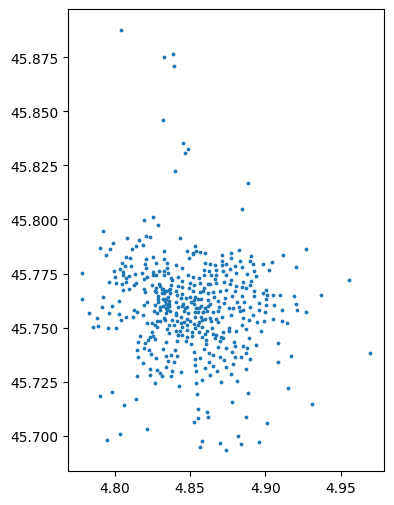

In [412]:
## Carte statique rapide
gdf_stations.plot(markersize=3, figsize=(6, 6))

### 9.2 Carte interactive avec Plotly

In [413]:
fig = px.scatter_map(
    df_stations, lat="lat", lon="lon",
    hover_name="nom", hover_data=["commune", "nbbornettes"],
    zoom=11, height=600, map_style="carto-positron",
)
fig.show()

### Exercice 9.1 – Une carte plus parlante

Reprenez la carte précédente et :
- colorez les points selon la **commune** ;
- faites varier la **taille** des points selon le nombre de bornettes ;
- ajoutez un titre.

<details><summary>💡 Indice</summary>

Paramètres `color=`, `size=` (et `size_max=`), `title=` de `px.scatter_map`.

</details>

In [ ]:
# REPONSES ICI

### Exercice 9.2 – Une station à moins de 300 m ?

On cherche les stations situées **à moins de 300 m de la place Bellecour** (latitude 45.7578, longitude 4.8320).

Attention : en EPSG:4326 les distances sont en degrés ! Il faut d'abord projeter les données dans un système métrique, par exemple le **Lambert 93** (`EPSG:2154`), avec `.to_crs()`.

1. Créez un point pour Bellecour et projetez-le, ainsi que les stations, en Lambert 93.
2. Calculez la distance (en mètres) de chaque station à Bellecour dans une colonne `dist_bellecour`.
3. Affichez les stations à moins de 300 m, de la plus proche à la plus éloignée.

<details><summary>💡 Indice</summary>

`gpd.GeoSeries(gpd.points_from_xy([lon], [lat]), crs="EPSG:4326").to_crs(2154)` crée le point projeté ; `GeoSeries.distance(point)` calcule les distances.

</details>

In [ ]:
#  REPONSES ICI

## Pour aller plus loin

- Quelle est la station la plus souvent vide à 9 h en semaine ? la plus souvent pleine ?
- Comparez l'activité pendant les vacances scolaires (zone A) et hors vacances.
- La part de l'électrique est-elle la même dans toutes les communes ?

**À la prochaine séance**, nous cartographierons ces indicateurs (cartes de chaleur, cartes choroplèthes par arrondissement, cartes animées).